<div dir="rtl" lang="he" xml:lang="he">
<font size=6> עיבוד נתונים - מעבדה א'</font>

<font size=5> מחברת colab </font>


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.odr import Model, ODR, RealData

In [3]:
file_path = r"/content/Qswiching-חלק2.xlsx" # Replace with your file path: r"/content/<your file name>.xlsx"
sheet_name = 0 # Replace with your sheet number
data = pd.read_excel(file_path, sheet_name=sheet_name)
data[:5]

,FERQ(KH),I(A),dI,dF,dP_pump(mW),P_pump(mW),B(M^-3 s^-1),dB
0,3.2,1.80,0.002887,0.028868,14.91,1451.04,2.437747e+28,2.504880e+26
1,3.5,1.83,0.002887,0.028868,15.66,1478.20,2.483376e+28,2.630880e+26
2,4.0,1.86,0.002887,0.028868,16.45,1505.36,2.529005e+28,2.763600e+26
3,4.4,1.89,0.002887,0.028868,17.26,1532.52,2.574634e+28,2.899680e+26
4,5.1,1.92,0.002887,0.028868,18.10,1559.68,2.620262e+28,3.040800e+26


<div dir="rtl" lang="he" xml:lang="he">

---
<h1>
<font size=5><b>3. בחירת x, $\Delta$x, y, $\Delta$y </b></font>
</h1>

כעת, נבחר את העמודות המתאימות מתוך הנתונים, לשם ביצוע ההתאמה. ניתן לבחור את העמודות לפי שם (השורה הראשונה בעמודה) או לחילופין לפי האינדקס של העמודה (0, 1, 2...). שוב, נדפיס את השורות הראשונות מתוך העמודות שנבחרו.

---

In [4]:
def choose_columns(columns):
    x = data.iloc[:,columns[0]]
    delta_x = data.iloc[:,columns[1]]
    y = data.iloc[:,columns[2]]
    delta_y = data.iloc[:,columns[3]]
    return x, delta_x, y, delta_y

<div dir="rtl" lang="he" xml:lang="he">

---
<h1>
<font size=5><b>4. התאמה לנתונים</b></font>
</h1>

נשתמש באלגוריתם ODR (או Orthogonal Distance Regression) לביצוע ההתאמה. אלגוריתם זה מתאים במקרה של תלות בין משתנים. בניגוד לבעיית המינימיזציה הסטנדרטית בשארים הפחותים, שם ההתחיסות הינה רק למרחק האנכי בין נקודות הדאטא וקו ההתאמה, ODR מבצע מינימיזציה ביחס למרחק האורתוגונלי, מה שמטייב את ההתאמה.
מתודת ODR מתוך הספריה SciPy מצריך הגדרת פונקציית התאמה ומתן ניחושים התחלתיים לפרמטרים. ראו להלן מספר פונקציות התאמה שימושיות, לדוגמא.

---

In [5]:
def function(A, x):
    pass # Define your function. See some examples below.

def linear(A, x):
    return A[1] * x + A[0]

def polynomial(A, x):
    return A[2] * x**2 + A[1] * x + A[0]

def optics(A, x):
    return A[1] * x / (x - A[1]) + A[0]

def exponential(A, x):
    return A[2] * np.exp(A[1] * x) + A[0]

def sinusoidal(A, x):
    return A[3] * np.sin(A[1] * x + A[2]) + A[0]

def ours(A,x):
    return A[1]/x+A[0]

def qswitch_freq(A, x):
    tau_a = 0.230  # 230 us = 0.230 ms (כדי שהתדירות תצא ב-kHz)
    P_th = A[0]
    beta = 0.4
    return 1.0 / (tau_a * np.log((x - beta * A[0]) / (x - A[0])))

<div dir="rtl" lang="he" xml:lang="he">
 תוכלו להתנסות בבחירת פונקציות התאמה שונות וניחושים התחלתיים שונים:

<div dir="rtl" lang="he" xml:lang="he">
 כעת, נבצע התאמה לנתונים לפי המודל הפונקציונלי הנבחר, באמצעות אלגוריתם ODR:

In [6]:
def odr_fit(fit_func, initial_guesses, x, delta_x, y, delta_y):
    model = Model(fit_func)
    odr_data = RealData(x, y, sx=delta_x, sy=delta_y)
    odr = ODR(data=odr_data, model=model, beta0=initial_guesses)
    output = odr.run()

    fit_params = output.beta
    fit_params_error = output.sd_beta
    fit_cov = output.cov_beta
    return fit_params, fit_params_error, fit_cov, output

<div dir="rtl" lang="he" xml:lang="he">

ננתח את הפלט של אלגוריתם ODR:

1. `fit_params`:

הפרמטרים המשוערים של המודל. אלו הם הערכים האופטימליים של הפרמטרים, המתאימים ביותר לנתונים לפי אלגוריתם ODR. הפרמטרים ניתנים לפי אינדקס בסדר עולה: $a_0,a_1,a_2,...$
2. `fit_params_error`:

השגיאה של הפרמטרים המשוערים. ערכים אלו מצביעים על אי הוודאות או השונות באומדני הפרמטרים. שגיאות הפרמטרים ניתנות לפי אינדקס בסדר עולה: $\Delta a_0,\Delta a_1,\Delta a_2,...$
3. `fit_cov`:

מטריצת השונות של הפרמטרים המשוערים. מטריצה ​​זו מספקת מידע על הקורלציה בין צמדי פרמטרים והשונות המשותפת שלהם:

\begin{bmatrix}
\text{Cov}(a_0, a_0) & \text{Cov}(a_0, a_1) & \text{Cov}(a_0, \dots) \\
\text{Cov}(a_1, a_0) & \text{Cov}(a_1, a_1) & \text{Cov}(a_1, \dots) \\
\text{Cov}(\dots, a_0) & \text{Cov}(\dots, a_1) & \text{Cov}(\dots, \dots)
\end{bmatrix}

<div dir="rtl" lang="he" xml:lang="he">

---
<h1>
<font size=5><b>5. חישוב השארים והמדדים הסטטיסטיים</b></font>
</h1>

נחשב את ערכי השארים (residuals) ואת $\chi^2_{red}, p-value$, באופן מפורש.

---

In [7]:
def calc_stats(x, y, fit_params, output):
    residuals = y - fit_func(fit_params, x)
    degrees_of_freedom = len(x) - len(fit_params)
    chi2 = output.sum_square
    chi2_red = chi2/degrees_of_freedom
    p_val = stats.chi2.sf(chi2, degrees_of_freedom)
    return residuals, degrees_of_freedom, chi2_red, p_val

<div dir="rtl" lang="he" xml:lang="he">

נסביר את משמעות הערכים שהדפסנו:

1. `residuals`:

שארים מתארים את ההפרש בין ערכי הנתונים והערכים החזויים מהמודל. הם מציינים עד כמה המודל מתאים לכל נקודת נתונים בודדת. הפרשים קטנים מעידים על התאמה טובה, ולהיפך.

2. `degrees_of_freedom`:

דרגות חופש (DOF) בהקשר של מודל רגרסיה מתייחס למספר המדידות מהנתונים פחות מספר פרמטרי ההתאמה.

3. `chi2_red`:

חי בריבוע מצומצם ($\chi^2_{red}$) הינו חי בריבוע חלקי מספר דרגות החופש. הוא מספק מדד למידת ההתאמה של המודל לנתונים, תוך התחשבות במספר הפרמטרים המוערכים. ערך קרוב ל-1 מצביע על התאמה טובה, בעוד שערכים גדולים או פחות מ-1 מצביעים על התאמה שאינה מיטבית.
3. `p_val`:

ערך ה-p נגזר מהתפלגות של חי בריבוע ומציין את ההסתברות לקבל ערך חי בריבוע
הקטן בערכו מהערך שקיבלנו מההתאמה, ובמילים אחרות:
$p[\chi^2<\chi^2_{fit}]$.

ערך p בטווח >0.05 או < 0.95 מצביע על כך שהמודל מתאים היטב לנתונים, בעוד שערך p קיצוני, <0.05 או > 0.95 מצביע על כך שהמודל עשוי להיות לא מתאים.


ערכים סטטיסטיים אלה יחד מספקים הערכה מקיפה של התאמת המודל הנבחר לנתונים, ומסייע לבחון את תקפות ההנחות השונות (ביחס לצורה הפונקציונלית של המודל, הערכת השגיאות, וכו...).
    


<div dir="rtl" lang="he" xml:lang="he">

---
<h1>
<font size=5><b>6. הדפסת פרמטרי ההתאמה ושגיאותיהם, והמדדים הסטטיסטיים הרלוונטיים</b></font>
</h1>

---

In [8]:
def print_output(fit_params, fit_params_error, chi2_red, p_val, degrees_of_freedom):
    for i in range(len(fit_params)):
        print(f"a[{i}]: {fit_params[i]} \u00B1 {fit_params_error[i]} ({(abs(fit_params_error[i]/fit_params[i]))*100}% error)")
    print(f"chi squared reduced = {chi2_red:.5f} \u00B1 {np.sqrt(2/degrees_of_freedom)}")
    print(f"p-probability = {p_val:.5e}")
    print(f"DOF = {degrees_of_freedom}")

<div dir="rtl" lang="he" xml:lang="he">

כעת, נבצע את כל תהליך ביצוע ההתאמה והחישובים הנלווים, בבת אחת, ע"י קריאה לכל הפונקציות שראינו לעיל. ראשית נבחר את העמודות הרלוונטיות ונשרטט את הדאטא בלבד (אנא עשו בדיקת שפיות: האם זו התצורה שציפיתם לקבל?):

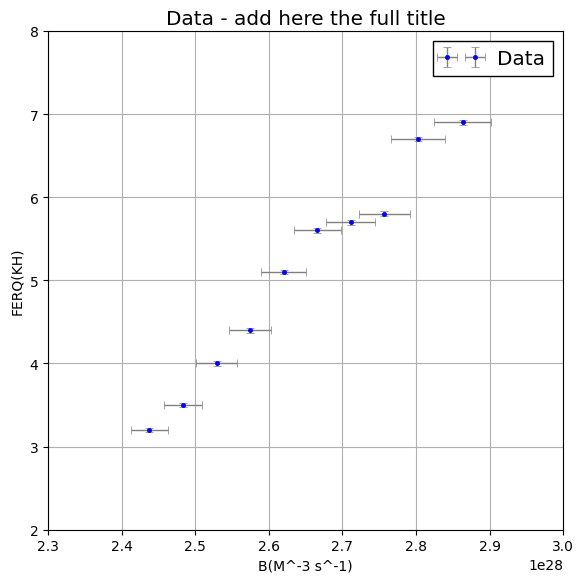

In [9]:
columns = [6,7, 0 ,3] # Define the columns indices to represent x, delta x, y, delta y.
x, delta_x, y, delta_y = choose_columns(columns)

# Clean data: Convert to numeric and drop NaN values to prevent plotting errors
clean_df = pd.DataFrame({'x': x, 'delta_x': delta_x, 'y': y, 'delta_y': delta_y})
for col in clean_df.columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')

clean_df = clean_df.dropna()

x = clean_df['x']
delta_x = clean_df['delta_x']
y = clean_df['y']
delta_y = clean_df['delta_y']

plt.close('all')
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
plt.style.use('classic')

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.errorbar(x, y, xerr=delta_x, yerr=delta_y, fmt='.b', label='Data', ecolor='gray') # Change the label if needed

ax.set_title('Data - add here the full title')  # Add here the full title for the fit
ax.set_xlabel(f'{data.columns[columns[0]]}') # Change x-axis label if needed
ax.set_ylabel(f'{data.columns[columns[2]]}') # Change y-axis label if needed

ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
fit_func = qswitch_freq
initial_guesses = [1.9e28] # Threshold parameter guess scaled to the order of magnitude of column B
fit_params, fit_params_error, fit_cov, output = odr_fit(fit_func, initial_guesses, x, delta_x, y, delta_y)
residuals, degrees_of_freedom, chi2_red, p_val = calc_stats(x, y, fit_params, output)
print_output(fit_params, fit_params_error, chi2_red, p_val, degrees_of_freedom)

a[0]: 1.8433220886214301e+28 ± 3.710704953490452e+26 (2.0130529419660927% error)
chi squared reduced = 28.25164 ± 0.4714045207910317
p-probability = 1.25424e-49
DOF = 9


<div dir="rtl" lang="he" xml:lang="he">
<font size=5 color="red"> אופציונאלי:</font>
נדפיס את הפלט הסטנדרטי המלא, לקבלת מידע מלא יותר על תהליך ביצוע ההתאמה (לפירוט, ראו את הדוקומנטציה).

[דוקומנטציה](https://docs.scipy.org/doc/scipy/reference/generated/scipy.odr.Output.html)

In [11]:
output.pprint()

Beta: [1.84332209e+28]
Beta Std Error: [3.71070495e+26]
Beta Covariance: [[4.87381612e+51]]
Residual Variance: 28.2516429047537
Inverse Condition #: 1.0
Reason(s) for Halting:
  Sum of squares convergence


<div dir="rtl" lang="he" xml:lang="he">

---
<h1>
<font size=5><b>7. שרטוט גרף הנתונים, פונקציית ההתאמה, וגרף השארים</b></font>
</h1>

נשרטט את ערכי הנתונים ושגיאותיהם (שימו לב שגם השגיאה בציר x משורטטת באיור זה, אם כי בשל מימדיה הקטנים היא לא נראית בבירור בגרף), ואת פונקציית ההתאמה שחישבנו ביחס אליהם, באיור השמאלי, ואילו את גרף השארים באיור הימני. תוכלו לשנות ולהתאים את פסקת הקוד הבאה לצרכיכם ולטעמכם, וכן להוסיף עוד עקומות במידת הנדרש. שימו לב שעליכם לערוך את הכותרות הראשיות לגרפים, כותרות הצירים, ולהוסיף יחידות.

---

/tmp/ipykernel_1533/431903848.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()


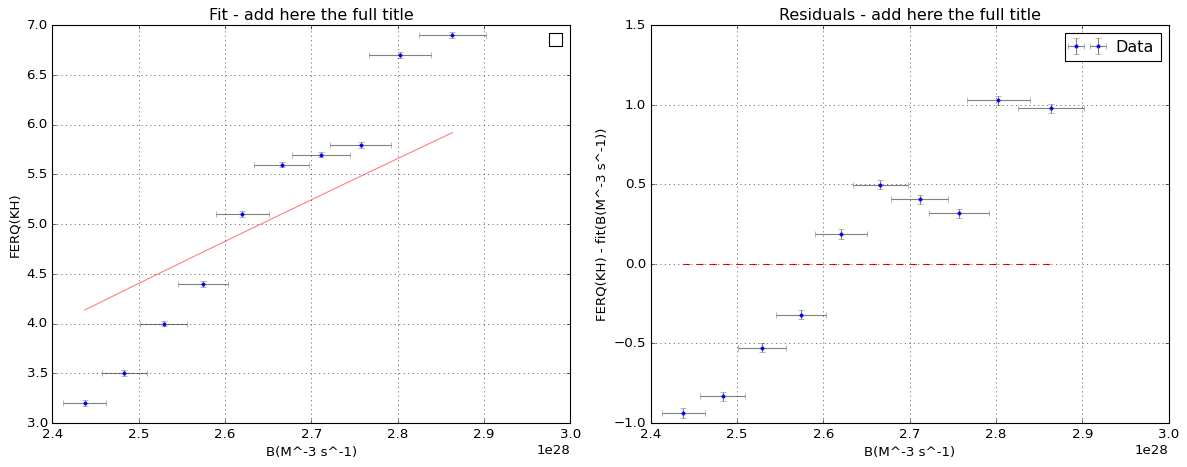

In [12]:
plt.close('all')
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
plt.style.use('classic')

fig.patch.set_facecolor('white')
for ax in axs:
    ax.set_facecolor('white')

x_fit = np.linspace(min(x), max(x), 10*len(x))
y_fit = fit_func(fit_params, x_fit)
axs[0].errorbar(x, y, xerr=delta_x, yerr=delta_y, fmt='.b',  ecolor='gray') # Change the label if needed
axs[0].plot(x_fit, y_fit, c='r', alpha=0.5) # Change the label if needed

# If you want to plot multiple functions, change here the relevant parameters (x, y, xerr, yerr, label). Otherwise, uncomment the 2 next lines:
#axs[0].errorbar(x + 0.2, y + 0.3, xerr=delta_x, yerr=delta_y, fmt='.g', ecolor='gray')
#axs[0].plot(x_fit + 0.2, y_fit + 0.3, label='Fit', c='k', alpha=0.5)

axs[0].set_title('Fit - add here the full title')  # Add here the full title for the fit
axs[0].set_xlabel(f'{data.columns[columns[0]]}') # Change x-axis label if needed
axs[0].set_ylabel(f'{data.columns[columns[2]]}') # Change y-axis label if needed

axs[0].grid(True)
axs[0].legend()

axs[1].errorbar(x, residuals, xerr=delta_x, yerr=delta_y, fmt='.b', label="Data", ecolor='gray')
axs[1].hlines(0, min(x), max(x), colors='r', linestyles='dashed')

axs[1].set_title('Residuals - add here the full title') # Add here the full title for the residuals
axs[1].set_xlabel(f'{data.columns[columns[0]]}') # Change column names if needed
axs[1].set_ylabel(f'{data.columns[columns[2]]} - fit({data.columns[columns[0]]})') # Change column names if needed

axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()